# A Photometric Na/Fe and O/Fe Estimator for Red-Giant Stars in Globular Clusters

**Dust-corrected Hubble colours, measured against each cluster's own ridgeline, predict sodium and oxygen abundances for stars in clusters the model has never seen.**

> Setup, data preparation and helper functions are collapsed. Every number and figure is computed from them, so rerunning the notebook refreshes the whole report.

### The idea in plain words
Globular clusters contain stars of different "generations". They differ in sodium and oxygen, and Hubble ultraviolet colours are sensitive to this. If that link is strong and simple enough, we can **estimate a star's Na/Fe and O/Fe from photometry alone**, and so extend chemistry to the many stars that have photometry but no spectrum.

To make that work we do three things:

1. **Remove interstellar dust** from every star's magnitudes and colours, using each cluster's dust amount and a standard extinction law. (Earlier work showed the Hubble data were not corrected.)
2. **Measure each star against its own cluster's red-giant ridgeline**, because what matters is how a star differs from its neighbours in the same cluster, not its absolute colour.
3. **Test only on whole clusters the model never saw**, so the result reflects a method that can be applied to new clusters.

### The population the method applies to
A photometric estimator needs a clearly defined population. We define it using **only photometry and the cluster ridgeline**, never the abundances, so the same rule can be applied to stars with no spectrum:

* the star has all five Hubble filters and passes the usual magnitude cuts;
* its cluster has a dust-corrected HUGS ridgeline, and the star lies within that ridgeline's magnitude range (so the star can be dereddened and referenced to the ridgeline);
* the star lies within **0.05 mag of its cluster's ridgeline in the optical colour (F606W−F814W)**, a red-giant-branch membership and photometric-quality condition.

We also show what happens if the 0.05 mag cut is applied to *all* colours (Section 3). It looks attractive in raw error, and it is a trap.

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 11})

PROJECT_DIR = Path().resolve()
while PROJECT_DIR.name != 'spectroscopy-regression' and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

TARGETS = ['Na/Fe', 'O/Fe']
BANDS = ['F275W', 'F336W', 'F438W', 'F606W', 'F814W']
SEQ = [('F275W', 'F336W'), ('F336W', 'F438W'), ('F438W', 'F606W'), ('F606W', 'F814W')]
RANGES = {'F275W_abs': (2, 10), 'F336W_abs': (0, 6), 'F438W_abs': (-2, 5), 'F606W_abs': (-5, 4), 'F814W_abs': (-5, 3)}
OFFSET_CUT = 0.05                               # mag
MINUS = '\u2212'

In [2]:
funnel = {}
df = pd.concat([pd.read_csv('data/Na_Fe_training_data.csv'), pd.read_csv('data/Na_Fe_TEST_DATA.csv')], ignore_index=True)
funnel['Pooled catalogue (train + test files)'] = len(df)
for c, (lo, hi) in RANGES.items():
    df = df[df[c].isna() | ((df[c] >= lo) & (df[c] <= hi))]
funnel['Pass the magnitude-range cuts'] = len(df)
df = df[df[[b + '_abs' for b in BANDS]].notna().all(axis=1)].copy()
funnel['Have all five Hubble filters'] = len(df)

Atab = pd.read_csv('data/GC_extinction_per_cluster.csv').set_index('NGC')
harris_feh = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
df['FeH'] = df['Fe/H'].fillna(df['NGC'].map(harris_feh))
df['EBV'] = df['NGC'].map(Atab['EBV'])

# remove dust:  M_0 = M_obs - A ;  colour_0 = colour_obs - (A_X - A_Y)
for b in BANDS:
    df[b + '_0'] = df[b + '_abs'] - df['NGC'].map(Atab['A_' + b])
for x, y in SEQ:
    df[f'c_{x}{y}_raw'] = df[x + '_abs'] - df[y + '_abs']
    df[f'c_{x}{y}'] = df[x + '_0'] - df[y + '_0']

# offset of every star from its own cluster's dust-corrected ridgeline, at the star's own brightness
for x, y in SEQ:
    df[f'd_{x}{y}'] = np.nan
for n, g in df.groupby('NGC'):
    f = Path(f'data/GC_Ridgelines_dereddened/NGC{n}_F814W_ridge.csv')
    if not f.exists():
        continue
    r = pd.read_csv(f)
    r = r[r['low_conf'].astype(str) == 'False'].dropna().sort_values('F814W_abs')
    if len(r) < 3:
        continue
    m = g['F814W_0'].to_numpy()
    inside = (m >= r['F814W_abs'].min()) & (m <= r['F814W_abs'].max())
    for x, y in SEQ:
        ridge = np.interp(m, r['F814W_abs'], r[f'{x}-{y}'])
        df.loc[g.index, f'd_{x}{y}'] = np.where(inside, g[f'c_{x}{y}'].to_numpy() - ridge, np.nan)

C4 = [f'c_{x}{y}' for x, y in SEQ]; R4 = [f'c_{x}{y}_raw' for x, y in SEQ]; D4 = [f'd_{x}{y}' for x, y in SEQ]
df['has_ridge'] = df[D4].notna().all(axis=1)
funnel['Cluster has a ridgeline and star is inside its magnitude range (can be dereddened and referenced)'] = int(df.has_ridge.sum())
df['optical_ok'] = df['d_F606WF814W'].abs() <= OFFSET_CUT
S2 = df[df.has_ridge]                                    # ridgeline available
S3 = S2[S2.optical_ok].copy()                            # PRIMARY population: + optical offset within 0.05 mag
S4 = S2[(S2[D4].abs() <= OFFSET_CUT).all(axis=1)].copy() # sensitivity: offset cut on ALL colours
funnel['Optical offset |\u0394(F606W' + MINUS + 'F814W)| \u2264 0.05 mag  (PRIMARY POPULATION)'] = len(S3)
S3.to_csv('data/Stars_ridge_sample.csv', index=False)

FEATURE_SETS = {
    'Old setup (raw colours)':         ['F606W_abs'] + R4 + ['FeH'],
    'Dust-corrected colours':          ['F606W_0'] + C4 + ['FeH'],
    'Dust-corrected + ridgeline offsets': ['F606W_0'] + C4 + D4 + ['FeH'],
}
CAND_SETS = ['Dust-corrected colours', 'Dust-corrected + ridgeline offsets']     # sets the selection may choose between
clusters = np.array(sorted(S3['NGC'].unique()))

In [3]:
class Average:
    def __init__(self, makers): self.makers = makers
    def fit(self, X, y): self.models = [m().fit(X, y) for m in self.makers]; return self
    def predict(self, X): return np.mean([m.predict(X) for m in self.models], axis=0)

class Augmented:
    """Fit a model on the real training stars plus synthetic copies. Only ever used on TRAINING data."""
    def __init__(self, maker, kind, k, s, seed=0): self.maker, self.kind, self.k, self.s, self.seed = maker, kind, k, s, seed
    def fit(self, X, y):
        sc = StandardScaler().fit(X); Xs = sc.transform(X); rng = np.random.default_rng(self.seed)
        if self.kind == 'jitter':
            Xa = np.vstack([Xs + rng.normal(0, self.s, Xs.shape) for _ in range(self.k)]); ya = np.tile(y, self.k)
        else:                                            # mixup: convex combinations of pairs of training stars
            i, j = rng.integers(0, len(y), len(y) * self.k), rng.integers(0, len(y), len(y) * self.k)
            lam = rng.beta(self.s, self.s, len(y) * self.k)[:, None]
            Xa, ya = lam * Xs[i] + (1 - lam) * Xs[j], lam[:, 0] * y[i] + (1 - lam[:, 0]) * y[j]
        self.sc, self.m = sc, self.maker().fit(np.vstack([Xs, Xa]), np.r_[y, ya])
        return self
    def predict(self, X): return self.m.predict(self.sc.transform(X))

def ET(): return ExtraTreesRegressor(200, min_samples_leaf=5, n_jobs=-1, random_state=0)
def RF(): return RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0)
def svr(C): return lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.05))
def ridge(): return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
MODELS = {'Ridge': ridge, 'SVR (C=0.3)': svr(0.3), 'SVR (C=1)': svr(1), 'SVR (C=3)': svr(3),
          'ExtraTrees': ET, 'RandomForest': RF, 'ExtraTrees + SVR': lambda: Average([ET, svr(1)])}
mse = lambda p, y: float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))

def cluster_folds(groups, n_folds=5, seed=0):
    return np.array_split(np.random.default_rng(seed).permutation(np.unique(groups)), n_folds)

def grouped_cv(maker, X, y, groups, reps=3, n_folds=5):
    """Mean squared error with whole clusters held out (mean over random cluster partitions)."""
    out = []
    for rep in range(reps):
        P = np.zeros(len(y))
        for fold in cluster_folds(groups, n_folds, seed=rep):
            te = np.isin(groups, fold); P[te] = maker().fit(X[~te], y[~te]).predict(X[te])
        out.append(mse(P, y))
    return float(np.mean(out))

def grouped_cv_predict(maker, X, y, groups, n_folds=5, seed=0):
    P = np.zeros(len(y))
    for fold in cluster_folds(groups, n_folds, seed=seed):
        te = np.isin(groups, fold); P[te] = maker().fit(X[~te], y[~te]).predict(X[te])
    return P

def select_spec(train, target, reps=2):
    d = train.dropna(subset=[target]); y, g = d[target].to_numpy(), d['NGC'].to_numpy()
    table = pd.DataFrame({mn: {fs: grouped_cv(mk, d[FEATURE_SETS[fs]].to_numpy(), y, g, reps) for fs in CAND_SETS} for mn, mk in MODELS.items()})
    fs, mn = table.stack().idxmin()
    return fs, mn, table

def run_split(pop, test_clusters, target, reps=2):
    """Hold out whole clusters; pick (inputs, model) on the training clusters only; refit; score once on the held-out clusters."""
    d = pop.dropna(subset=[target]); is_test = d['NGC'].isin(test_clusters).to_numpy()
    tr, te = d[~is_test], d[is_test]
    fs, mn, table = select_spec(tr, target, reps)
    cols = FEATURE_SETS[fs]; model = MODELS[mn]().fit(tr[cols].to_numpy(), tr[target].to_numpy())
    ptr, pte = model.predict(tr[cols].to_numpy()), model.predict(te[cols].to_numpy())
    return dict(features=fs, model=mn, table=table, train=tr, test=te, p_train=ptr, p_test=pte,
                mse_train=mse(ptr, tr[target]), mse_test=mse(pte, te[target]), mse_baseline=mse(np.full(len(te), tr[target].mean()), te[target]))

## 1. The sample

The table is the full accounting of which stars are used and why. Nothing is removed using the abundances.

In [4]:
ft = pd.DataFrame({'stars': funnel}).rename_axis('step')
ft['% of previous'] = (ft['stars'] / ft['stars'].shift(1) * 100).round(0)
display(ft)
lab = pd.DataFrame({'stars with label': [S3['Na/Fe'].notna().sum(), S3['O/Fe'].notna().sum()], 'clusters': [S3.dropna(subset=['Na/Fe']).NGC.nunique(), S3.dropna(subset=['O/Fe']).NGC.nunique()],
                    'target variance': [S3['Na/Fe'].var(), S3['O/Fe'].var()]}, index=['Na/Fe', 'O/Fe']).round(3)
display(Markdown('**Primary population (labels available)**'))
display(lab)
display(Markdown(f'The abundances are *not* used to choose stars, so the cuts do not bias the labels: the mean Na/Fe is {S2["Na/Fe"].mean():.3f} before and {S3["Na/Fe"].mean():.3f} after the optical-offset cut (mean O/Fe {S2["O/Fe"].mean():.3f} \u2192 {S3["O/Fe"].mean():.3f}).'))

,stars,% of previous
step,,
Pooled catalogue (train + test files),683,NaN
Pass the magnitude-range cuts,664,97.0
Have all five Hubble filters,494,74.0
Cluster has a ridgeline and star is inside its magnitude range (can be dereddened and referenced),386,78.0
Optical offset |Δ(F606W−F814W)| ≤ 0.05 mag (PRIMARY POPULATION),366,95.0


**Primary population (labels available)**

,stars with label,clusters,target variance
Na/Fe,366,24,0.072
O/Fe,284,24,0.095


The abundances are *not* used to choose stars, so the cuts do not bias the labels: the mean Na/Fe is 0.323 before and 0.312 after the optical-offset cut (mean O/Fe 0.148 → 0.161).

**In plain words.** We lose the stars from clusters without a Hubble ridgeline (including the very large ω Centauri), because without a ridgeline we cannot tell how a star differs from its cluster. The 0.05 mag optical cut then removes only a handful more stars; it just throws out stars sitting well off the red-giant track in a colour that should not depend on chemistry, which are likely blends, mismeasured, or not on the red-giant branch.

## 2. What the ridgeline offsets look like

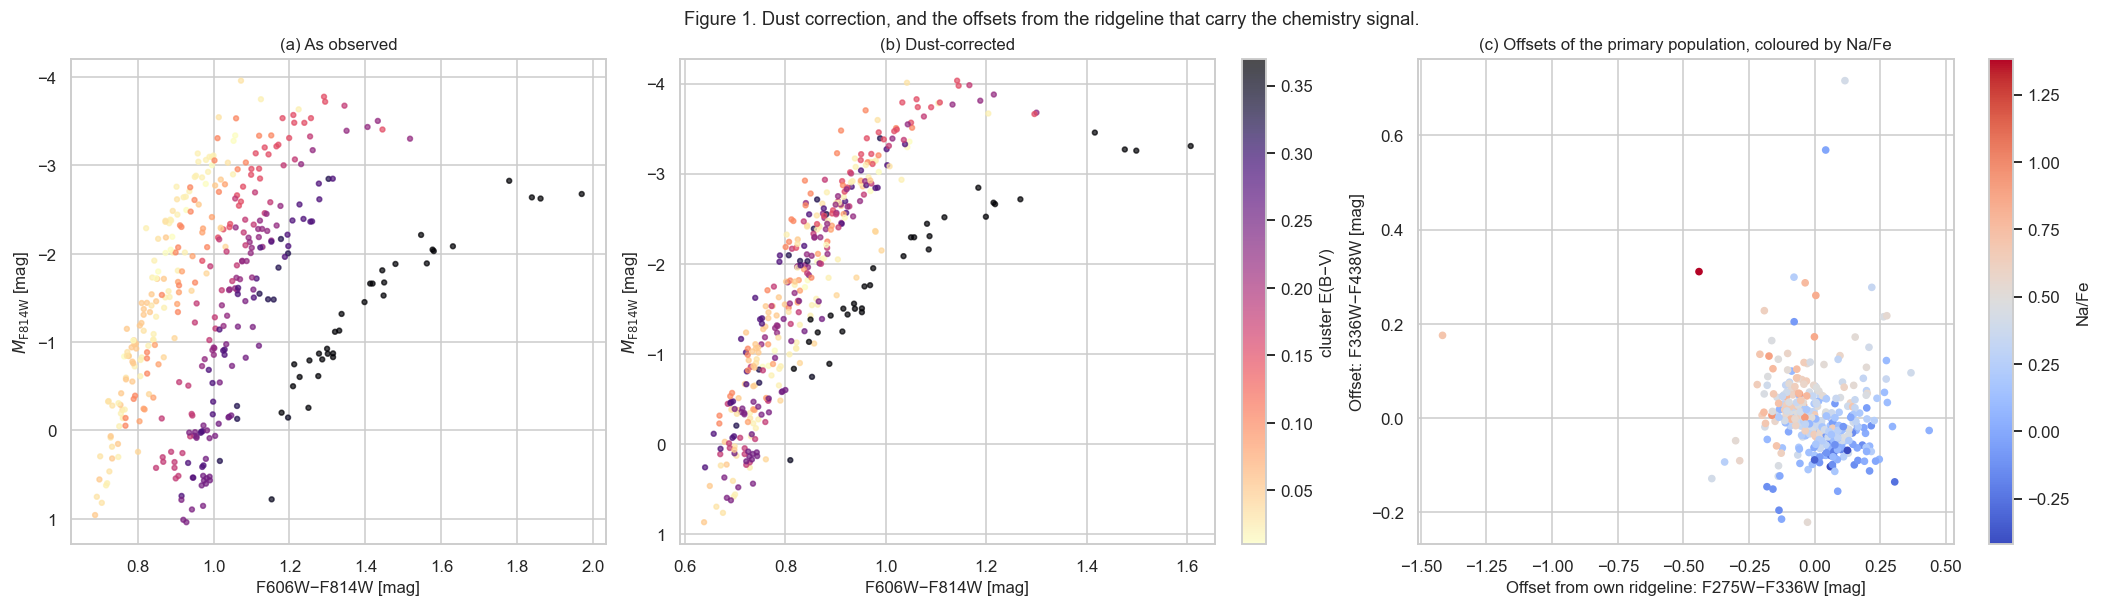

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), constrained_layout=True)
cmap = plt.cm.magma_r; norm = plt.Normalize(df.EBV.min(), df.EBV.max())
for ax, (xc, yc, title) in zip(axes[:2], [('c_F606WF814W_raw', 'F814W_abs', '(a) As observed'), ('c_F606WF814W', 'F814W_0', '(b) Dust-corrected')]):
    sc = ax.scatter(S2[xc], S2[yc], c=S2.EBV, cmap=cmap, norm=norm, s=10, alpha=0.7)
    ax.invert_yaxis(); ax.set_xlabel('F606W' + MINUS + 'F814W [mag]'); ax.set_ylabel(r'$M_{\mathrm{F814W}}$ [mag]'); ax.set_title(title)
fig.colorbar(sc, ax=axes[1], label='cluster E(B' + MINUS + 'V)')
sc = axes[2].scatter(S3['d_F275WF336W'], S3['d_F336WF438W'], c=S3['Na/Fe'], cmap='coolwarm', s=16)
axes[2].set_xlabel('Offset from own ridgeline: F275W' + MINUS + 'F336W [mag]'); axes[2].set_ylabel('Offset: F336W' + MINUS + 'F438W [mag]')
axes[2].set_title('(c) Offsets of the primary population, coloured by Na/Fe'); fig.colorbar(sc, ax=axes[2], label='Na/Fe')
fig.suptitle('Figure 1. Dust correction, and the offsets from the ridgeline that carry the chemistry signal.', fontsize=12)
plt.show()

**In plain words (Figure 1).** (a) As observed, clusters are spread sideways by dust (dot colour). (b) After correction most stars from all clusters fall on a much narrower red-giant track (the dark dots that stay redder are the very metal-rich cluster NGC 6388). (c) Measured against its own cluster's ridgeline, each star gets a small ultraviolet offset. Red (sodium-rich) and blue (sodium-poor) stars are partly separated, which is the signal the regression uses, but they overlap, so we expect a partial prediction, not a perfect one.

## 3. Why we do **not** cut on the ultraviolet offsets

Cutting on the *optical* offset removes stars that are not clean red-giant-branch stars. Cutting on *all four* offsets (including the ultraviolet ones) sounds like more of the same, but the ultraviolet offsets **are the signal**: they are what separates the stellar generations. Restricting them to ±0.05 mag keeps only stars sitting right on the ridgeline. We test this directly.

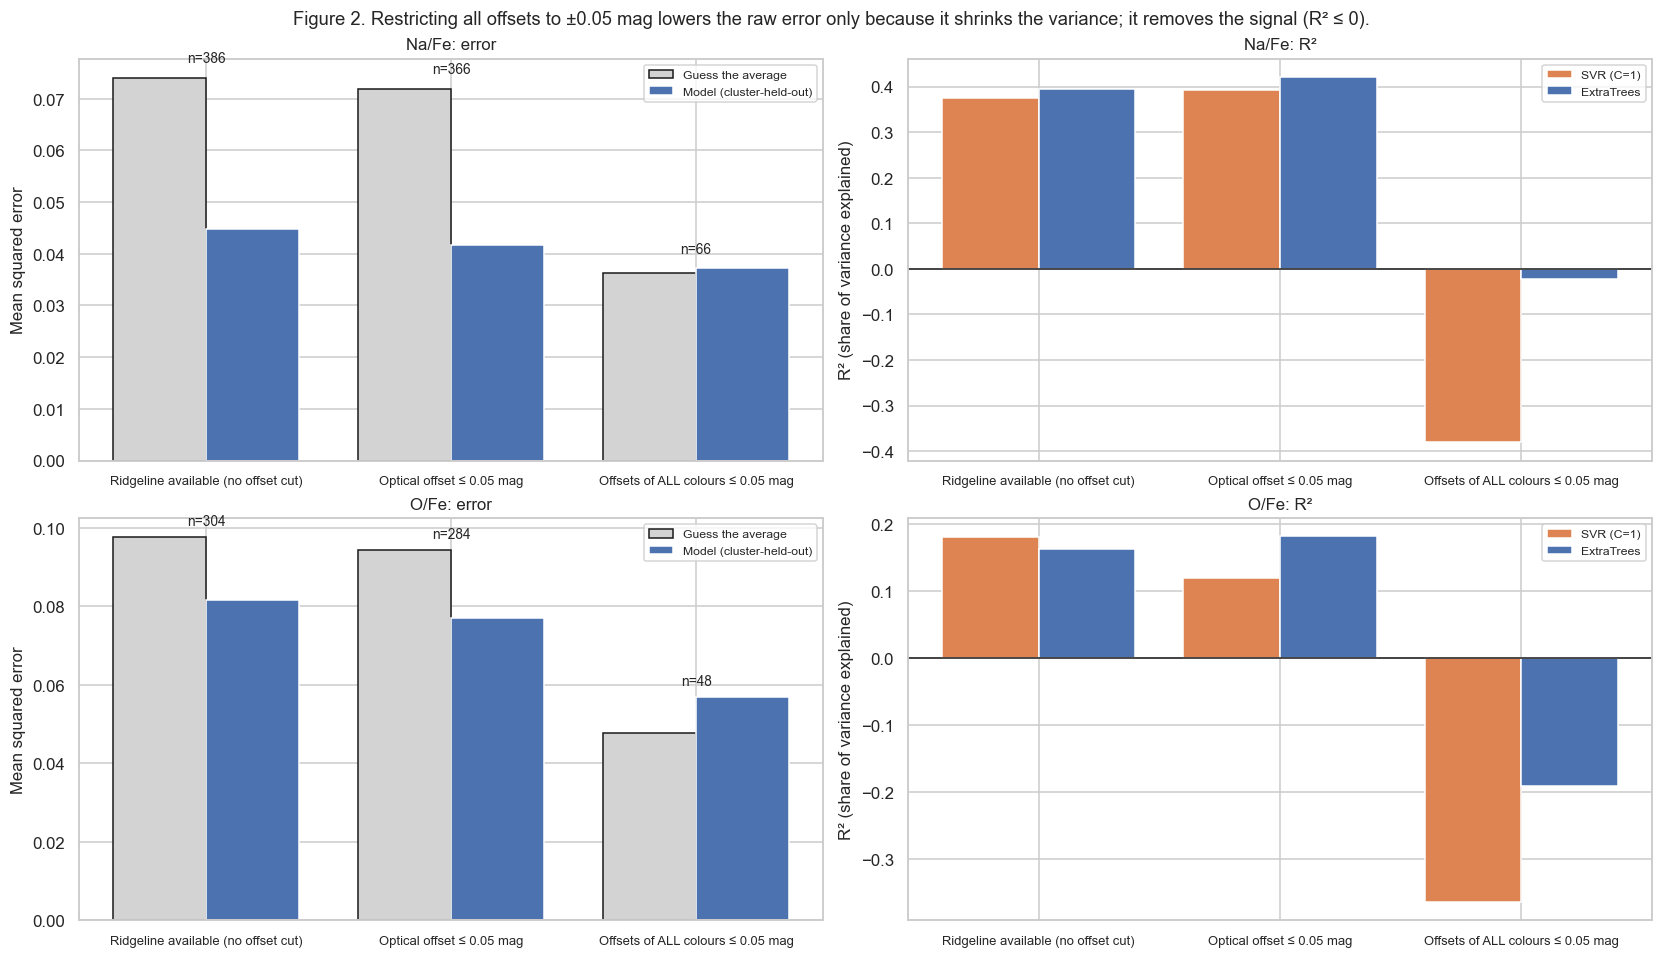

n  variance    MSE  \
target population                           model                              
Na/Fe  Ridgeline available (no offset cut)  SVR (C=1)   386     0.074  0.046   
                                            ExtraTrees  386     0.074  0.045   
       Optical offset ≤ 0.05 mag  [PRIMARY] SVR (C=1)   366     0.072  0.044   
                                            ExtraTrees  366     0.072  0.042   
       Offsets of ALL colours ≤ 0.05 mag    SVR (C=1)    66     0.036  0.050   
                                            ExtraTrees   66     0.036  0.037   
O/Fe   Ridgeline available (no offset cut)  SVR (C=1)   304     0.098  0.080   
                                            ExtraTrees  304     0.098  0.082   
       Optical offset ≤ 0.05 mag  [PRIMARY] SVR (C=1)   284     0.094  0.083   
                                            ExtraTrees  284     0.094  0.077   
       Offsets of ALL colours ≤ 0.05 mag    SVR (C=1)    48     0.048  0.065   
                                            ExtraTrees   48     0.048  0.057   

                                                           R2  
target population                           model              
Na/Fe  Ridgeline available (no offset cut)  SVR (C=1)   0.376  
                                            ExtraTrees  0.395  
       Optical offset ≤ 0.05 mag  [PRIMARY] SVR (C=1)   0.392  
                                            ExtraTrees  0.421  
       Offsets of ALL colours ≤ 0.05 mag    SVR (C=1)  -0.380  
                                            ExtraTrees -0.023  
O/Fe   Ridgeline available (no offset cut)  SVR (C=1)   0.180  
                                            ExtraTrees  0.163  
       Optical offset ≤ 0.05 mag  [PRIMARY] SVR (C=1)   0.119  
                                            ExtraTrees  0.181  
       Offsets of ALL colours ≤ 0.05 mag    SVR (C=1)  -0.364  
                                            ExtraTrees -0.191

In [6]:
SENS = {'Ridgeline available (no offset cut)': S2, 'Optical offset \u2264 0.05 mag  [PRIMARY]': S3, 'Offsets of ALL colours \u2264 0.05 mag': S4}
rows = []
for target in TARGETS:
    for sname, pop in SENS.items():
        d = pop.dropna(subset=[target]); y, g = d[target].to_numpy(), d['NGC'].to_numpy()
        for mn in ['SVR (C=1)', 'ExtraTrees']:
            m_ = grouped_cv(MODELS[mn], d[FEATURE_SETS['Dust-corrected + ridgeline offsets']].to_numpy(), y, g, reps=5)
            rows.append(dict(target=target, population=sname, model=mn, n=len(d), variance=y.var(), MSE=m_, R2=1 - m_ / y.var()))
sens = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 2, figsize=(15, 8.6), constrained_layout=True)
for r_, target in enumerate(TARGETS):
    d = sens[(sens.target == target) & (sens.model == 'ExtraTrees')]
    x = np.arange(len(d)); w = 0.38
    axes[r_, 0].bar(x - w / 2, d['variance'], w, label='Guess the average', color='lightgray', edgecolor='k')
    axes[r_, 0].bar(x + w / 2, d['MSE'], w, label='Model (cluster-held-out)', color='C0')
    for xi, (n, v, m_) in enumerate(zip(d.n, d['variance'], d.MSE)): axes[r_, 0].text(xi, max(v, m_) + 0.003, f'n={n}', ha='center', fontsize=9)
    axes[r_, 0].set_xticks(x); axes[r_, 0].set_xticklabels([s.replace('  [PRIMARY]', '') for s in d.population], fontsize=8.5); axes[r_, 0].set_ylabel('Mean squared error')
    axes[r_, 0].set_title(f'{target}: error'); axes[r_, 0].legend(fontsize=8)
    for mn, col in zip(['SVR (C=1)', 'ExtraTrees'], ['C1', 'C0']):
        dd = sens[(sens.target == target) & (sens.model == mn)]
        axes[r_, 1].bar(np.arange(len(dd)) + (0.2 if mn == 'ExtraTrees' else -0.2), dd.R2, 0.4, label=mn, color=col)
    axes[r_, 1].axhline(0, color='k', lw=1); axes[r_, 1].set_xticks(np.arange(len(d))); axes[r_, 1].set_xticklabels([s.replace('  [PRIMARY]', '') for s in d.population], fontsize=8.5)
    axes[r_, 1].set_ylabel('R\u00b2 (share of variance explained)'); axes[r_, 1].set_title(f'{target}: R\u00b2'); axes[r_, 1].legend(fontsize=8)
fig.suptitle('Figure 2. Restricting all offsets to \u00b10.05 mag lowers the raw error only because it shrinks the variance; it removes the signal (R\u00b2 \u2264 0).', fontsize=12)
plt.show()
display(sens.round(3).set_index(['target', 'population', 'model']))

**In plain words (Figure 2).** Left: the grey bar is the error from always guessing the average. In the right-most group the grey bar is much shorter, because the cut left stars that are all alike, so guessing the average already looks good, and the model's error looks small too. Right: judged by the share of variance actually explained (R², where 0 means no better than guessing), the model explains nothing in that group. Raw error is not comparable across populations, so **we compare populations only by R²**, and the "all offsets ≤ 0.05" cut would give a falsely flattering MSE with no real skill. This is reported here so that readers can see the cut was considered and why it is not used.

## 4. What each ingredient contributes (primary population)

Same stars, same cluster-held-out cross-validation; only the inputs change.

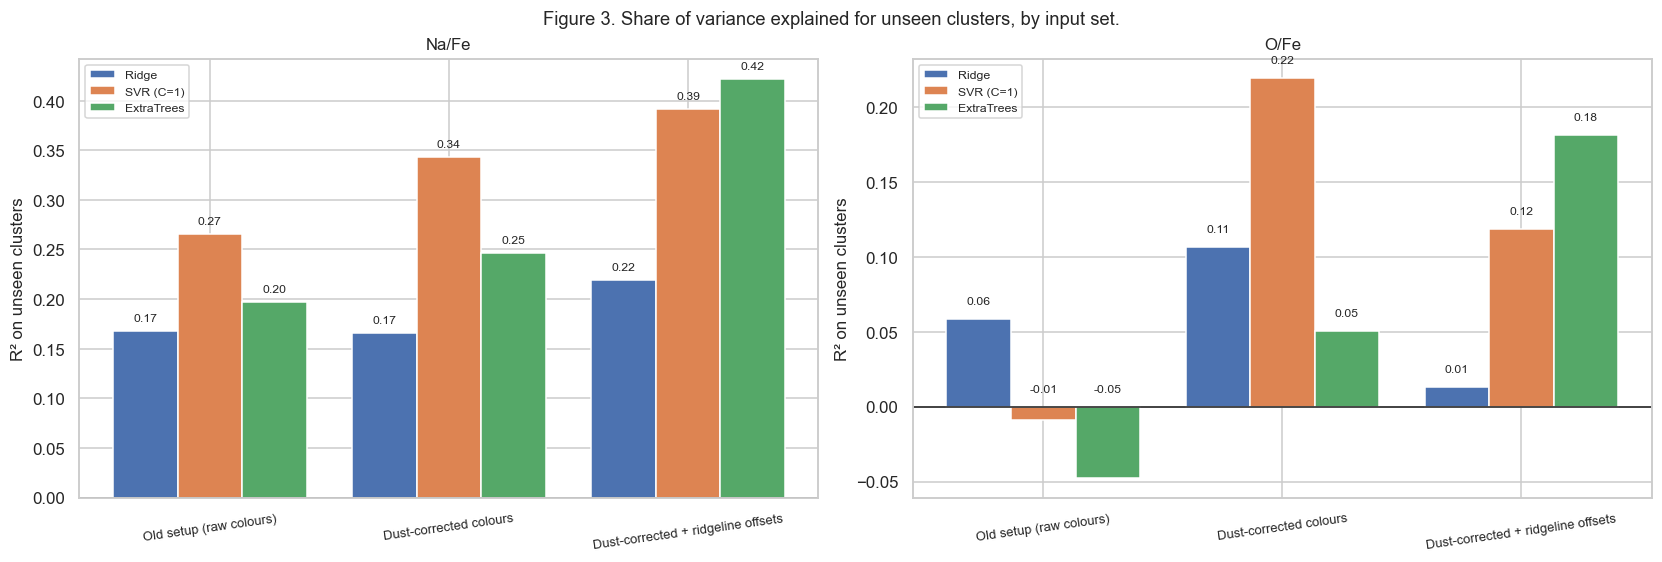

model                                      ExtraTrees   Ridge  SVR (C=1)
target inputs                                                           
Na/Fe  Dust-corrected + ridgeline offsets      0.0416  0.0561     0.0438
       Dust-corrected colours                  0.0542  0.0600     0.0472
       Old setup (raw colours)                 0.0578  0.0598     0.0528
O/Fe   Dust-corrected + ridgeline offsets      0.0772  0.0930     0.0831
       Dust-corrected colours                  0.0895  0.0842     0.0736
       Old setup (raw colours)                 0.0987  0.0888     0.0951

In [7]:
ABL_MODELS = ['Ridge', 'SVR (C=1)', 'ExtraTrees']
abl = []
for target in TARGETS:
    d = S3.dropna(subset=[target]); y, g = d[target].to_numpy(), d['NGC'].to_numpy()
    for fs, cols in FEATURE_SETS.items():
        for mn in ABL_MODELS:
            m_ = grouped_cv(MODELS[mn], d[cols].to_numpy(), y, g, reps=5)
            abl.append(dict(target=target, inputs=fs, model=mn, MSE=m_, R2=1 - m_ / y.var(), variance=y.var()))
abl = pd.DataFrame(abl)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    d = abl[abl.target == target]; x = np.arange(len(FEATURE_SETS)); w = 0.27
    for j, mn in enumerate(ABL_MODELS):
        v = [d[(d.inputs == fs) & (d.model == mn)].R2.iloc[0] for fs in FEATURE_SETS]
        bars = ax.bar(x + (j - 1) * w, v, w, label=mn)
        for b, vv in zip(bars, v): ax.text(b.get_x() + b.get_width() / 2, max(vv, 0) + 0.01, f'{vv:.2f}', ha='center', fontsize=8)
    ax.axhline(0, color='k', lw=1); ax.set_xticks(x); ax.set_xticklabels(list(FEATURE_SETS), fontsize=8.5, rotation=8)
    ax.set_ylabel('R\u00b2 on unseen clusters'); ax.set_title(target); ax.legend(fontsize=8)
fig.suptitle('Figure 3. Share of variance explained for unseen clusters, by input set.', fontsize=12)
plt.show()
display(abl.pivot_table(index=['target', 'inputs'], columns='model', values='MSE').round(4))

**In plain words (Figure 3).** Taller is better. Moving left to right we give the model better information: raw colours (the old setup), dust-corrected colours, and finally each star's offset from its own cluster's ridgeline. **Na/Fe:** every step helps, and the best result (ExtraTrees with the ridgeline offsets) is clearly above the old setup. **O/Fe:** the old setup is worst and dust correction helps, but adding the ridgeline offsets helps the tree models and not the SVR or ridge model, so the best O/Fe result is the dust-corrected SVR. In other words, the offsets reliably add information for sodium, but we cannot say that they do for oxygen. Differences of about 0.005 in MSE between models are within noise.

## 5. Train/test split and main result

* **Whole clusters are held out** (about one quarter), so the test measures prediction for clusters the model never saw.
* For each target, the best combination of input set and model (14 candidates) is chosen with cluster-held-out cross-validation **inside the training clusters only**; the held-out clusters are scored once.
* Because ~24 clusters make any single split noisy, the whole procedure (including selection) is repeated on many random splits (Section 6).

In [8]:
SEED = 42
test_clusters = np.sort(np.random.default_rng(SEED).choice(clusters, size=int(round(0.25 * len(clusters))), replace=False))
train_clusters = np.setdiff1d(clusters, test_clusters)
display(Markdown(f'**Test clusters ({len(test_clusters)}):** NGC ' + ', '.join(map(str, test_clusters)) + f' &nbsp;|&nbsp; **Training clusters ({len(train_clusters)}):** NGC ' + ', '.join(map(str, train_clusters))))
main = {t: run_split(S3, test_clusters, t, reps=3) for t in TARGETS}
tab = pd.DataFrame({t: {'selected inputs': r['features'], 'selected model': r['model'], 'train stars': len(r['train']), 'test stars': len(r['test']),
                        'train MSE': r['mse_train'], 'TEST MSE': r['mse_test'], 'test MSE if guessing the average': r['mse_baseline'],
                        'test R\u00b2': 1 - r['mse_test'] / r['mse_baseline']} for t, r in main.items()})
display(tab)

**Test clusters (6):** NGC 288, 5904, 6205, 6388, 6838, 7078 &nbsp;|&nbsp; **Training clusters (18):** NGC 104, 362, 1261, 1851, 2808, 3201, 4590, 4833, 5986, 6093, 6121, 6254, 6397, 6584, 6715, 6809, 6934, 7099

,Na/Fe,O/Fe
selected inputs,Dust-corrected + ridgeline offsets,Dust-corrected colours
selected model,RandomForest,SVR (C=1)
train stars,277,212
test stars,89,72
train MSE,0.017471,0.038786
TEST MSE,0.041931,0.090955
test MSE if guessing the average,0.062341,0.100478
test R²,0.327394,0.094776


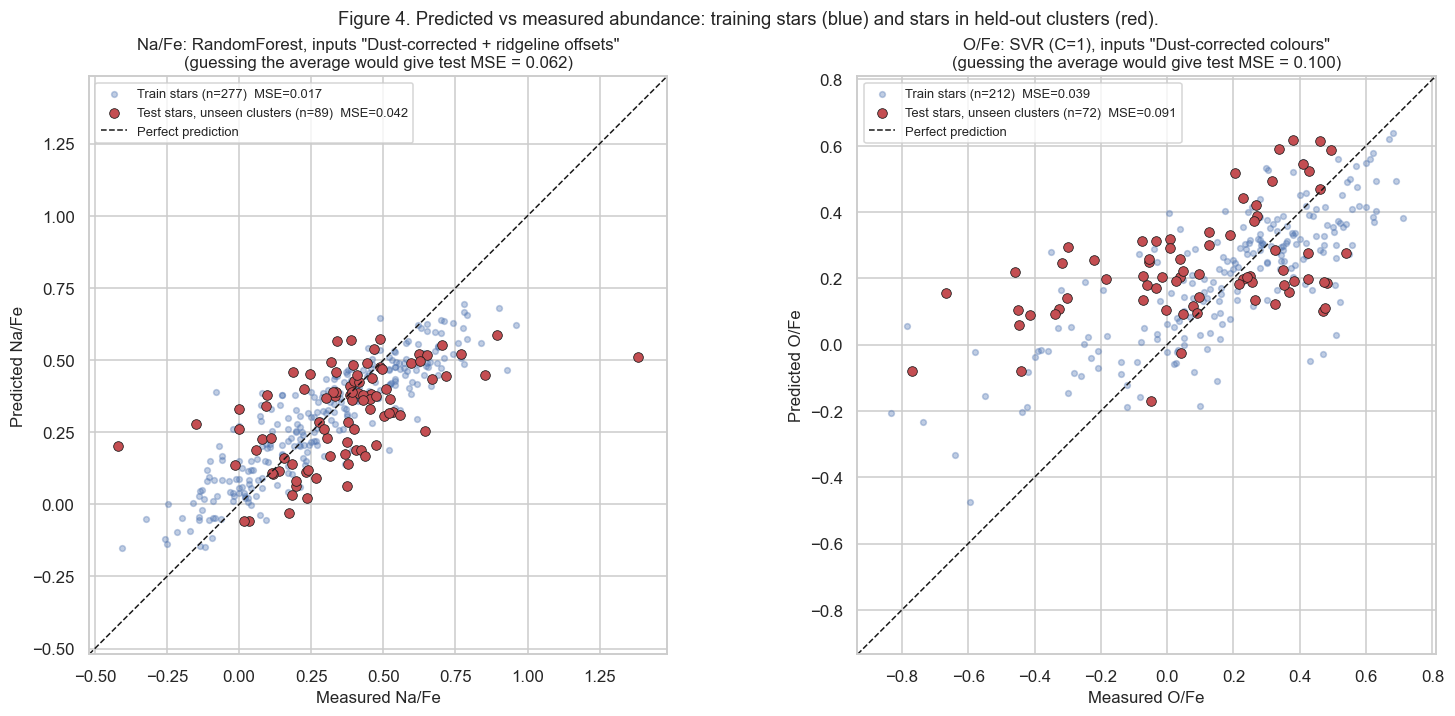

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    r = main[target]; ytr, yte = r['train'][target].to_numpy(), r['test'][target].to_numpy()
    lo = min(ytr.min(), yte.min(), r['p_train'].min(), r['p_test'].min()) - 0.1; hi = max(ytr.max(), yte.max(), r['p_train'].max(), r['p_test'].max()) + 0.1
    ax.scatter(ytr, r['p_train'], s=14, alpha=0.35, color='C0', label=f'Train stars (n={len(ytr)})  MSE={r["mse_train"]:.3f}')
    ax.scatter(yte, r['p_test'], s=40, color='C3', edgecolor='k', linewidth=0.5, label=f'Test stars, unseen clusters (n={len(yte)})  MSE={r["mse_test"]:.3f}')
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='Perfect prediction')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel(f'Measured {target}'); ax.set_ylabel(f'Predicted {target}')
    ax.set_title(f'{target}: {r["model"]}, inputs "{r["features"]}"\n(guessing the average would give test MSE = {r["mse_baseline"]:.3f})')
    ax.legend(loc='upper left', fontsize=8.5)
fig.suptitle('Figure 4. Predicted vs measured abundance: training stars (blue) and stars in held-out clusters (red).', fontsize=12)
plt.show()

**In plain words (Figure 4).** Each dot is a star: measured abundance on the x-axis (from a spectrum), prediction from photometry alone on the y-axis. Dots on the dashed line are perfect. Blue stars were used to train the model; **red stars come from clusters the model never saw**. If the red dots follow the line about as well as the blue ones, the method generalises. This is one particular split of the clusters; the next section shows how much the result moves from split to split.

## 6. How much does it depend on which clusters are held out?

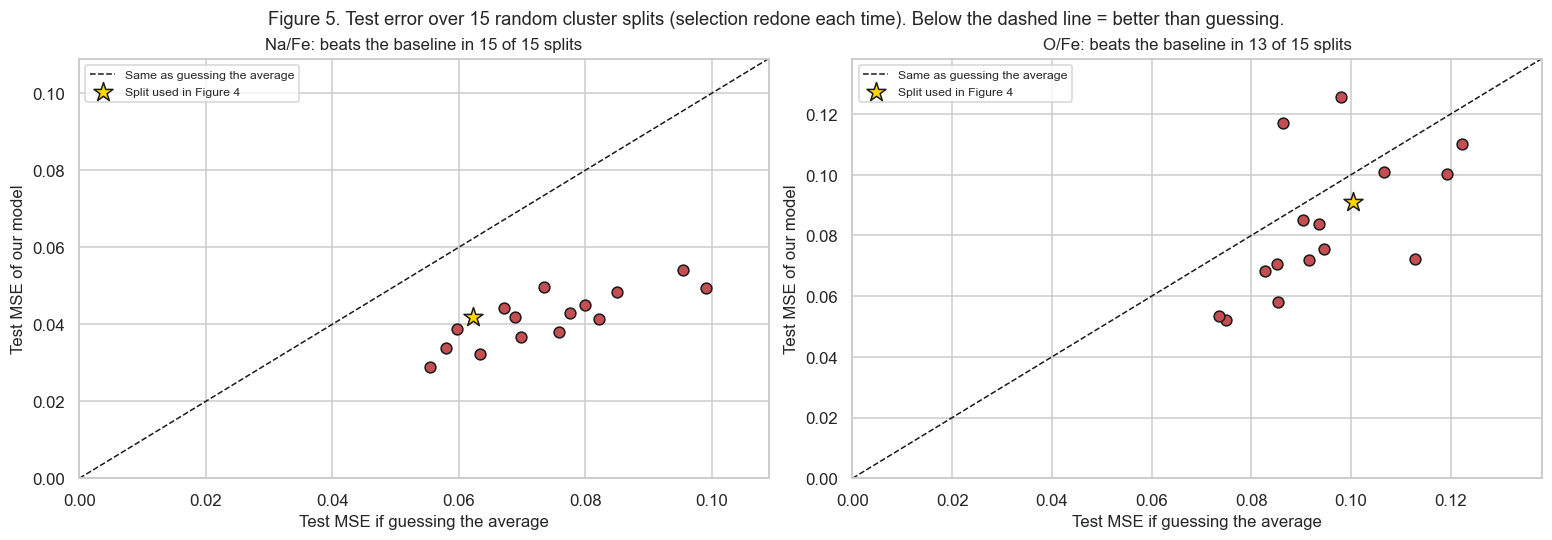

,mean_test_MSE,sd_test_MSE,mean_baseline_MSE,mean_R2,sd_R2,wins
target,,,,,,
Na/Fe,0.042,0.007,0.074,0.434,0.060,15
O/Fe,0.083,0.023,0.094,0.124,0.202,13


target  features                            model           
Na/Fe   Dust-corrected + ridgeline offsets  ExtraTrees           4
                                            ExtraTrees + SVR    10
                                            RandomForest         1
O/Fe    Dust-corrected + ridgeline offsets  ExtraTrees           2
                                            RandomForest         4
        Dust-corrected colours              Ridge                3
                                            SVR (C=1)            3
                                            SVR (C=3)            3
Name: times selected, dtype: int64

In [10]:
N_REPEATS = 15
rep_rows = []
for s in range(N_REPEATS):
    tc = np.sort(np.random.default_rng(1000 + s).choice(clusters, size=len(test_clusters), replace=False))
    for t in TARGETS:
        r = run_split(S3, tc, t, reps=1)
        rep_rows.append(dict(split=s, target=t, features=r['features'], model=r['model'], test_mse=r['mse_test'], baseline=r['mse_baseline'], train_mse=r['mse_train']))
rep = pd.DataFrame(rep_rows); rep['R2'] = 1 - rep.test_mse / rep.baseline
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for ax, t in zip(axes, TARGETS):
    d = rep[rep.target == t]
    ax.scatter(d.baseline, d.test_mse, s=50, edgecolor='k', color='C3')
    lim = [0, max(d.baseline.max(), d.test_mse.max(), main[t]['mse_baseline'], main[t]['mse_test']) * 1.1]
    ax.plot(lim, lim, 'k--', lw=1, label='Same as guessing the average'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.scatter([main[t]['mse_baseline']], [main[t]['mse_test']], s=170, marker='*', color='gold', edgecolor='k', zorder=5, label='Split used in Figure 4')
    ax.set_xlabel('Test MSE if guessing the average'); ax.set_ylabel('Test MSE of our model')
    ax.set_title(f'{t}: beats the baseline in {(d.test_mse < d.baseline).sum()} of {len(d)} splits'); ax.legend(fontsize=8)
fig.suptitle(f'Figure 5. Test error over {N_REPEATS} random cluster splits (selection redone each time). Below the dashed line = better than guessing.', fontsize=12)
plt.show()
g = rep.groupby('target')
display(g.agg(mean_test_MSE=('test_mse', 'mean'), sd_test_MSE=('test_mse', 'std'), mean_baseline_MSE=('baseline', 'mean'), mean_R2=('R2', 'mean'), sd_R2=('R2', 'std'), wins=('R2', lambda s: int((s > 0).sum()))).round(3))
display(rep.groupby(['target', 'features', 'model']).size().rename('times selected'))

**In plain words (Figure 5).** Each dot is one random choice of which clusters to hold out, and the whole pipeline, including model selection, is redone each time. Dots below the dashed line beat guessing the average. The star is the split of Figure 4. The spread of the dots is the honest uncertainty from having only about two dozen clusters.

## 7. Every star as a test star

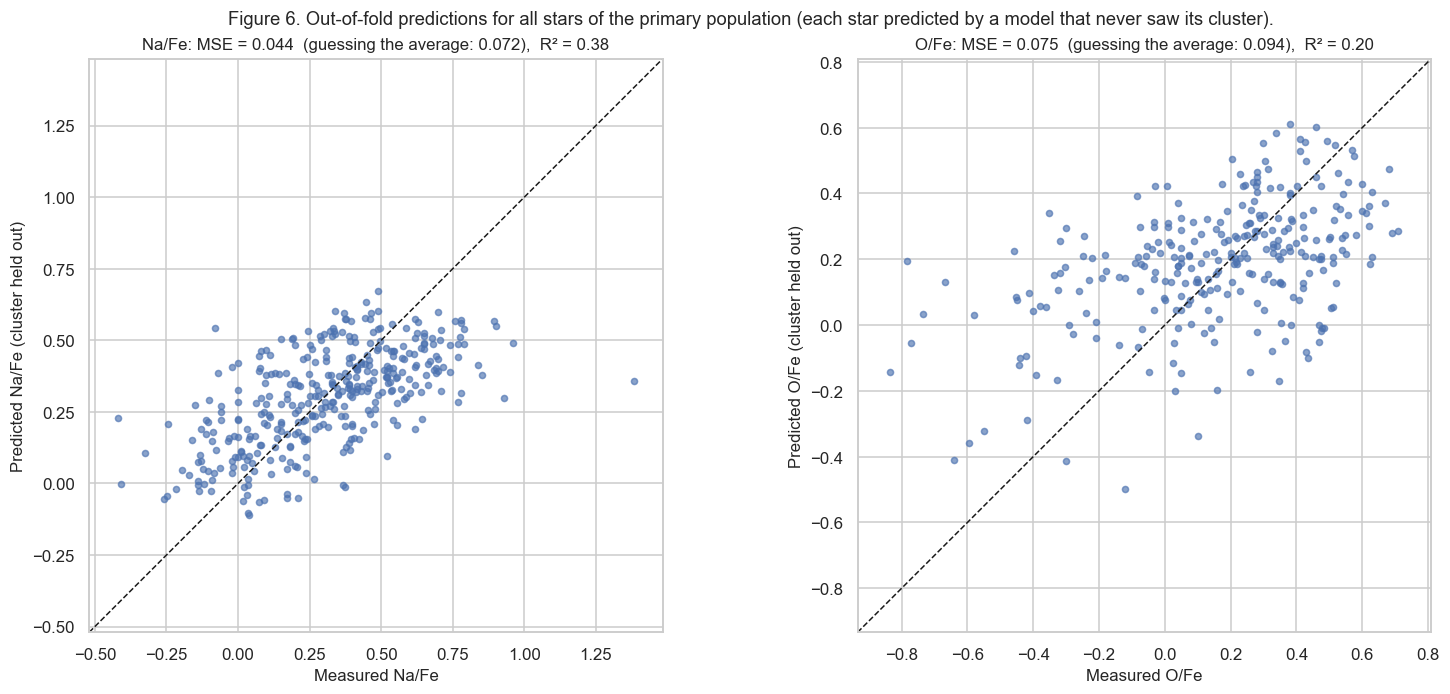

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), constrained_layout=True)
oof = {}
for ax, target in zip(axes, TARGETS):
    d = S3.dropna(subset=[target]); cols_t = FEATURE_SETS[main[target]['features']]
    y, g_ = d[target].to_numpy(), d['NGC'].to_numpy()
    P = grouped_cv_predict(MODELS[main[target]['model']], d[cols_t].to_numpy(), y, g_, seed=7)
    oof[target] = (mse(P, y), y.var())
    ax.scatter(y, P, s=16, alpha=0.65, color='C0')
    lo, hi = min(y.min(), P.min()) - 0.1, max(y.max(), P.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel(f'Measured {target}'); ax.set_ylabel(f'Predicted {target} (cluster held out)')
    ax.set_title(f'{target}: MSE = {oof[target][0]:.3f}  (guessing the average: {oof[target][1]:.3f}),  R\u00b2 = {1 - oof[target][0] / oof[target][1]:.2f}')
fig.suptitle('Figure 6. Out-of-fold predictions for all stars of the primary population (each star predicted by a model that never saw its cluster).', fontsize=12)
plt.show()

## 8. Can synthetic extra stars amplify the signal?

Small training sets can sometimes be helped by adding synthetic stars. We tested two standard techniques, applied **to training stars only** (the stars in held-out clusters are always real):

* **Noise jitter:** copies of each training star with small random changes to its inputs.
* **Mixup:** synthetic stars made by blending pairs of real training stars (inputs and abundance together).

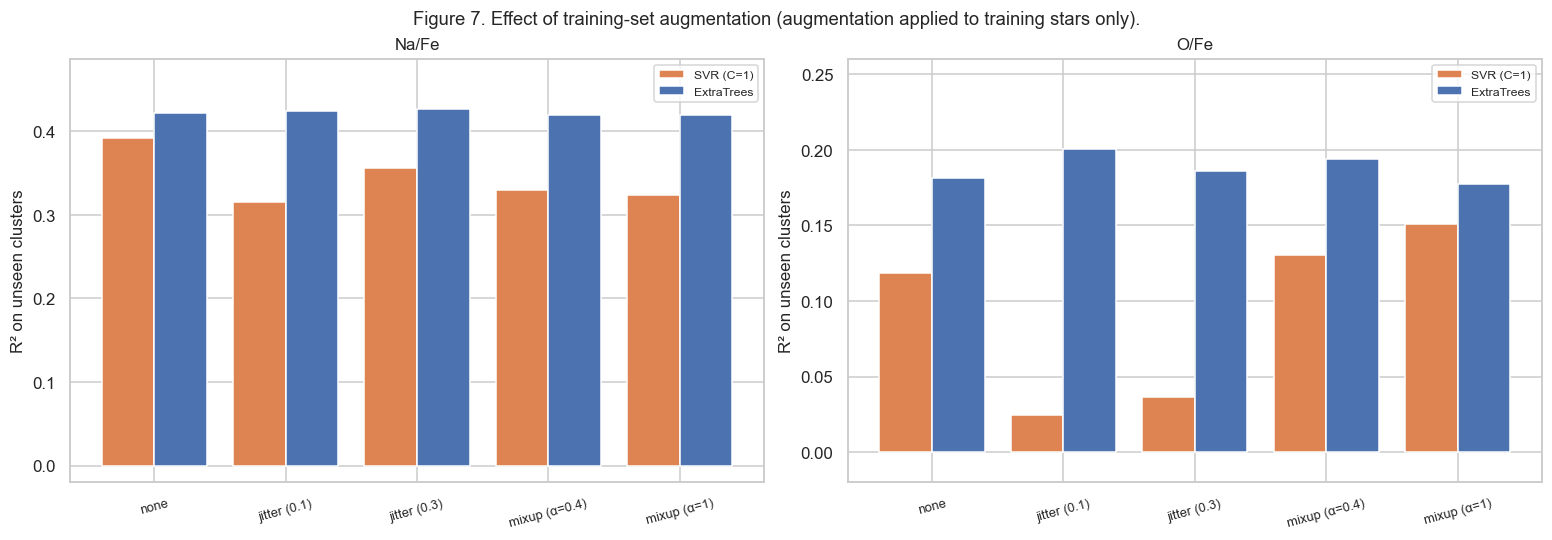

Best R² gain from any augmentation over no augmentation: **Na/Fe**: ExtraTrees +0.005, SVR (C=1) -0.036; **O/Fe**: ExtraTrees +0.019, SVR (C=1) +0.032

In [12]:
AUG = {'none': None, 'jitter (0.1)': ('jitter', 5, 0.1), 'jitter (0.3)': ('jitter', 5, 0.3), 'mixup (\u03b1=0.4)': ('mixup', 3, 0.4), 'mixup (\u03b1=1)': ('mixup', 3, 1.0)}
rows = []
for target in TARGETS:
    d = S3.dropna(subset=[target]); X, y, g_ = d[FEATURE_SETS['Dust-corrected + ridgeline offsets']].to_numpy(), d[target].to_numpy(), d['NGC'].to_numpy()
    for mn in ['SVR (C=1)', 'ExtraTrees']:
        for an, a in AUG.items():
            mk = MODELS[mn] if a is None else (lambda mk0=MODELS[mn], a=a: Augmented(mk0, *a))
            m_ = grouped_cv(mk, X, y, g_, reps=5)
            rows.append(dict(target=target, model=mn, augmentation=an, MSE=m_, R2=1 - m_ / y.var()))
aug = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    d = aug[aug.target == target]
    for j, (mn, col) in enumerate(zip(['SVR (C=1)', 'ExtraTrees'], ['C1', 'C0'])):
        dd = d[d.model == mn]; ax.bar(np.arange(len(dd)) + (j - 0.5) * 0.4, dd.R2, 0.4, label=mn, color=col)
    ax.set_xticks(np.arange(len(AUG))); ax.set_xticklabels(list(AUG), rotation=15, fontsize=8.5)
    ax.set_ylim(min(0, d.R2.min()) - 0.02, d.R2.max() + 0.06); ax.set_ylabel('R\u00b2 on unseen clusters'); ax.set_title(target); ax.legend(fontsize=8)
fig.suptitle('Figure 7. Effect of training-set augmentation (augmentation applied to training stars only).', fontsize=12)
plt.show()
aug_best = {t: aug[(aug.target == t) & (aug.augmentation != 'none')].groupby('model').R2.max() - aug[(aug.target == t) & (aug.augmentation == 'none')].set_index('model').R2 for t in TARGETS}
display(Markdown('Best R\u00b2 gain from any augmentation over no augmentation: ' + '; '.join(f'**{t}**: ' + ', '.join(f'{m} {v:+.3f}' for m, v in s.items()) for t, s in aug_best.items())))

**In plain words (Figure 7).** If augmentation amplified the signal, the bars would rise to the right. They do not. For the tree model (ExtraTrees, blue) the changes are small (about ±0.02 in R²) and within the split-to-split noise of Figure 5. For the SVR (orange), adding noise jitter clearly **hurts**, especially for O/Fe. Synthetic stars cannot add information that is not in the real ones; at best they act as a mild regulariser. We therefore **do not use augmentation**, and we do not claim a gain from it.

In [13]:
g = rep.groupby('target')
display(Markdown(f"""
## Summary of findings

| | **Na/Fe** | **O/Fe** |
|---|---|---|
| Stars in primary population (with label) | {S3['Na/Fe'].notna().sum()} | {S3['O/Fe'].notna().sum()} |
| Test MSE, held-out clusters (Figure 4 split) | **{main['Na/Fe']['mse_test']:.3f}** (R\u00b2 {1 - main['Na/Fe']['mse_test'] / main['Na/Fe']['mse_baseline']:.2f}) | **{main['O/Fe']['mse_test']:.3f}** (R\u00b2 {1 - main['O/Fe']['mse_test'] / main['O/Fe']['mse_baseline']:.2f}) |
| Train MSE (same split) | {main['Na/Fe']['mse_train']:.3f} | {main['O/Fe']['mse_train']:.3f} |
| **Test MSE, mean \u00b1 sd over {N_REPEATS} cluster splits** | **{g['test_mse'].mean()['Na/Fe']:.3f} \u00b1 {g['test_mse'].std()['Na/Fe']:.3f}** (average-guess: {g['baseline'].mean()['Na/Fe']:.3f}) | **{g['test_mse'].mean()['O/Fe']:.3f} \u00b1 {g['test_mse'].std()['O/Fe']:.3f}** (average-guess: {g['baseline'].mean()['O/Fe']:.3f}) |
| **R\u00b2 over splits (mean \u00b1 sd)** | **{g['R2'].mean()['Na/Fe']:.2f} \u00b1 {g['R2'].std()['Na/Fe']:.2f}** | **{g['R2'].mean()['O/Fe']:.2f} \u00b1 {g['R2'].std()['O/Fe']:.2f}** |
| Splits better than guessing | {int((rep[rep.target=='Na/Fe'].R2 > 0).sum())} of {N_REPEATS} | {int((rep[rep.target=='O/Fe'].R2 > 0).sum())} of {N_REPEATS} |
| All stars, out-of-fold R\u00b2 (Figure 6) | {1 - oof['Na/Fe'][0] / oof['Na/Fe'][1]:.2f} | {1 - oof['O/Fe'][0] / oof['O/Fe'][1]:.2f} |

**Take-away.** For red-giant stars in clusters with a Hubble ridgeline, and within 0.05 mag of the ridgeline in the optical colour, dust-corrected photometry referenced to each cluster's own ridgeline recovers a substantial part of the Na/Fe variance (about {g['R2'].mean()['Na/Fe']*100:.0f}% on average) and a smaller part of the O/Fe variance (about {g['R2'].mean()['O/Fe']*100:.0f}%) for **clusters the model has never seen**. The estimate is partial, not exact. It could be applied to unlabelled stars that satisfy the same photometric criteria. Two things we tried to "improve" the numbers did not stand up: cutting on the ultraviolet offsets removes the signal itself (Figure 2), and synthetic augmentation gives no reliable gain (Figure 7).
"""))


## Summary of findings

| | **Na/Fe** | **O/Fe** |
|---|---|---|
| Stars in primary population (with label) | 366 | 284 |
| Test MSE, held-out clusters (Figure 4 split) | **0.042** (R² 0.33) | **0.091** (R² 0.09) |
| Train MSE (same split) | 0.017 | 0.039 |
| **Test MSE, mean ± sd over 15 cluster splits** | **0.042 ± 0.007** (average-guess: 0.074) | **0.083 ± 0.023** (average-guess: 0.094) |
| **R² over splits (mean ± sd)** | **0.43 ± 0.06** | **0.12 ± 0.20** |
| Splits better than guessing | 15 of 15 | 13 of 15 |
| All stars, out-of-fold R² (Figure 6) | 0.38 | 0.20 |

**Take-away.** For red-giant stars in clusters with a Hubble ridgeline, and within 0.05 mag of the ridgeline in the optical colour, dust-corrected photometry referenced to each cluster's own ridgeline recovers a substantial part of the Na/Fe variance (about 43% on average) and a smaller part of the O/Fe variance (about 12%) for **clusters the model has never seen**. The estimate is partial, not exact. It could be applied to unlabelled stars that satisfy the same photometric criteria. Two things we tried to "improve" the numbers did not stand up: cutting on the ultraviolet offsets removes the signal itself (Figure 2), and synthetic augmentation gives no reliable gain (Figure 7).


## 9. Scope, limitations and what a reader should be told

* **Population.** The estimator is defined for stars with five Hubble filters, in clusters with a HUGS ridgeline, within 0.05 mag of that ridgeline in F606W−F814W. It is not claimed for other stars (for example in ω Centauri or other clusters without ridgelines) or for stars with large optical offsets. The selection uses only photometry, so the same rule can be applied to unlabelled stars. The effect of each step on the sample is in the table in Section 1.
* **The full-sample result is also reported.** The earlier notebook (`abundance_regression_dereddened.ipynb`) evaluates all 494 stars; it shows lower R² (about 0.27 for Na/Fe and 0.15 for O/Fe on average), partly because it includes stars with no ridgeline offsets. Restricting the population improves R² in a way that is only valid for the restricted population.
* **Choices not made by looking at test results.** The optical-offset threshold and the decision to drop stars without ridgelines were fixed by the physical meaning of the cut, then reported. Cutting on all offsets and augmentation were evaluated and *rejected* because they remove the signal or give no reliable gain; both results are shown.
* **Small number of clusters.** About two dozen clusters, a few with only a handful of stars. Split-to-split variation (Figure 5) is large; quote the repeated-split averages, not a single split.
* **Label noise.** Abundances come from several papers and methods with their own offsets; this probably limits the achievable accuracy.
* **Dust correction.** Uses a catalogue E(B−V), a fixed R_V = 3.1 law and one red-giant temperature; a small residual remains in the ultraviolet colours.
* **Model selection** among 14 candidates was done inside the training clusters only and repeated for every split, so the quoted test errors include its optimism.

**Possible next steps:** per-paper offset correction of the abundance labels; ridgelines on the F438W axis to cover more stars; fitting E(B−V) per cluster; joint prediction of Na/Fe and O/Fe; propagating measurement errors.